In [7]:
import pandas as pd


df = pd.read_csv("dataset_pisang.csv")
df

,panjang,diameter,berat,tebal_kulit,varietas
0,11,3.8,90,3.0,kepok
1,12,4.0,100,3.0,kepok
2,10,3.5,85,3.0,kepok
3,10,3.6,87,3.0,kepok
4,11,3.9,95,3.0,kepok
5,14,3.2,60,2.0,raja
6,15,3.5,65,2.0,raja
7,13,3.0,58,2.0,raja
8,14,3.3,62,2.0,raja
9,15,3.4,61,2.0,raja


In [8]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 20 entries, 0 to 19
Data columns (total 5 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   panjang      20 non-null     int64  
 1   diameter     20 non-null     float64
 2   berat        20 non-null     int64  
 3   tebal_kulit  20 non-null     float64
 4   varietas     20 non-null     str    
dtypes: float64(2), int64(2), str(1)
memory usage: 932.0 bytes


In [10]:
df.describe()


,panjang,diameter,berat,tebal_kulit
count,20.000000,20.000000,20.00000,20.000000
mean,13.500000,3.430000,106.30000,2.625000
std,1.960129,0.354074,33.97073,0.425348
min,10.000000,2.800000,58.00000,2.000000
25%,12.000000,3.175000,80.00000,2.375000
50%,14.000000,3.500000,110.00000,2.750000
75%,15.000000,3.725000,132.50000,3.000000
max,16.000000,4.000000,155.00000,3.000000


In [18]:
df.head(10)


,panjang,diameter,berat,tebal_kulit,varietas
0,11,3.8,90,3.0,kepok
1,12,4.0,100,3.0,kepok
2,10,3.5,85,3.0,kepok
3,10,3.6,87,3.0,kepok
4,11,3.9,95,3.0,kepok
5,14,3.2,60,2.0,raja
6,15,3.5,65,2.0,raja
7,13,3.0,58,2.0,raja
8,14,3.3,62,2.0,raja
9,15,3.4,61,2.0,raja


In [19]:
df.tail(10)


,panjang,diameter,berat,tebal_kulit,varietas
10,12,2.8,120,2.5,ambon
11,13,3.0,125,2.5,ambon
12,15,3.2,130,2.5,ambon
13,13,2.9,122,2.5,ambon
14,14,3.1,128,2.5,ambon
15,15,3.5,140,3.0,cavendish
16,16,3.8,150,3.0,cavendish
17,15,3.6,145,3.0,cavendish
18,16,3.7,148,3.0,cavendish
19,16,3.8,155,3.0,cavendish


In [23]:
df.sample(5, random_state=42)

,panjang,diameter,berat,tebal_kulit,varietas
0,11,3.8,90,3.0,kepok
17,15,3.6,145,3.0,cavendish
15,15,3.5,140,3.0,cavendish
1,12,4.0,100,3.0,kepok
8,14,3.3,62,2.0,raja


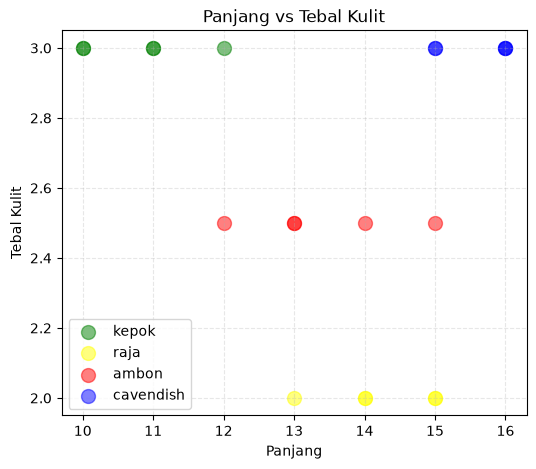

In [36]:
import matplotlib.pyplot as plt

kepok = df[df["varietas"] == "kepok"]
raja = df[df["varietas"] == "raja"]
ambon = df[df["varietas"] == "ambon"]
cavendish = df[df["varietas"] == "cavendish"]

plt.figure(figsize=(6,5))
plt.scatter(kepok["panjang"], kepok["tebal_kulit"], s=100, color="green", alpha=0.5, label="kepok")
plt.scatter(raja["panjang"], raja["tebal_kulit"], s=100, color="yellow", alpha=0.5, label="raja")
plt.scatter(ambon["panjang"], ambon["tebal_kulit"], s=100, color="red", alpha=0.5, label="ambon")
plt.scatter(cavendish["panjang"], cavendish["tebal_kulit"], s=100, color="blue", alpha=0.5, label="cavendish")
plt.title("Panjang vs Tebal Kulit")
plt.xlabel("Panjang")
plt.ylabel("Tebal Kulit")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.3)
plt.show()

In [52]:
from sklearn.linear_model import LogisticRegression

from sklearn.model_selection import train_test_split

from sklearn.metrics import accuracy_score

from sklearn.preprocessing import StandardScaler

X = df[["panjang", "diameter", "berat", "tebal_kulit"]]
y = df["varietas"]

X_train, X_test, y_train, y_test = train_test_split(
    X,y, test_size=0.2, random_state=42
)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

model = LogisticRegression()

model.fit(X_train_scaled, y_train)

y_pred = model.predict(X_test_scaled)

print(f"Accuracy :", accuracy_score(y_test, y_pred))


Accuracy : 1.0


In [56]:
data_baru = pd.DataFrame([[11,4,80,3]], columns=["panjang", "diameter", "berat", "tebal_kulit"])
data_baru_scaled = scaler.transform(data_baru)

prediksi = model.predict(data_baru_scaled)[0]
presentase = max(model.predict_proba(data_baru_scaled)[0])
print(f"Model mempredikasi {prediksi} dengan tingkat keyakinan {presentase*100:.2f}%")

Model mempredikasi kepok dengan tingkat keyakinan 88.13%
